# Experiment 3: Centrifugal-Pump SRF Model

**Aim:** Study pressure rise, pump head, velocity components, and temperature rise in a simplified rotating annular passage.

**Numerical method:** Reduced-order polar single-rotating-frame model with prescribed radial/tangential velocities and steady thermal transport.

> **Scope:** This is not a blade-resolved pump CFD model. It is intended to expose centrifugal pressure rise, relative velocity, and loss heating.

This Google Colab notebook is self-contained. It reconstructs the tested solver inside the temporary Colab runtime, runs it, displays quantitative plots and an inline field contour, and packages every output file for download.

> **Colab workflow:** Choose a run mode, use **Runtime > Run all**, then download the results ZIP from the final cell. `quick` is only a workflow check; use `lab` or an approved `custom` case for submission.

## Parameters

Use `quick` to test the workflow, `lab` for the prescribed case, and `custom` only when changing the form values for the assignment.

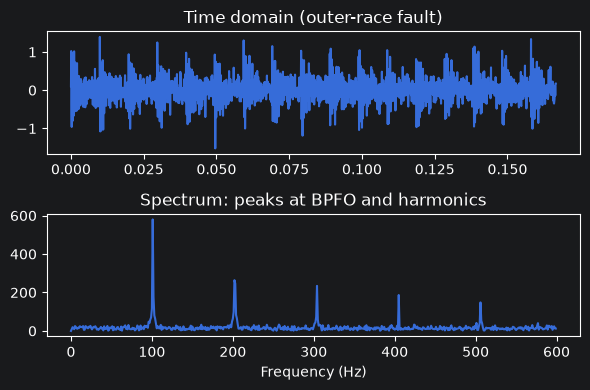

In [7]:
import numpy as np
import matplotlib.pyplot as plt

fs = 12000
t = np.arange(0, 1, 1/fs)
fr, n, dD = 30, 9, 0.25
bpfo = (n/2) * fr * (1 - dD)   # about 101 Hz

x = 0.2 * np.random.randn(len(t))
for k in np.arange(0, 1, 1/bpfo):
    i = int(k * fs)
    m = min(200, len(t) - i)
    x[i:i+m] += np.exp(-np.arange(m)/30) * np.sin(2*np.pi*3000*np.arange(m)/fs)

env = np.abs(np.fft.rfft(np.abs(x) - np.abs(x).mean()))
f = np.fft.rfftfreq(len(x), 1/fs)

fig, ax = plt.subplots(2, 1, figsize=(6, 4))
ax[0].plot(t[:2000], x[:2000])
ax[0].set_title("Time domain (outer-race fault)")
ax[1].plot(f[:600], env[:600])
ax[1].set_title("Spectrum: peaks at BPFO and harmonics")
ax[1].set_xlabel("Frequency (Hz)")
plt.tight_layout()
plt.savefig("fft.png", dpi=300)
plt.show()

## Run the solver

## Numerical summary

## Quantitative plots

## Inline field visualization

This preview removes the need for ParaView during the basic laboratory workflow. The VTK file is still included in the downloaded results for optional advanced post-processing.

## Download results

## 7. Compulsory assignment

Run 1000, 2000, and 3000 rpm at fixed Reynolds number. Plot pump head against $RPM^2$ and test the expected near-linear scaling.

## Report checklist

- State the governing equations and boundary conditions.
- Report the complete parameter set and grid.
- Include residual or error history.
- Include the required quantitative comparison.
- Include at least one correctly labelled inline field figure; VTK/ParaView figures are optional unless specifically assigned.
- Distinguish observed numerical behaviour from physical interpretation.
- State the limitations of the supplied teaching model.